In [1]:
""""
Raw Data Sources
      │
      ▼
Data Ingestion
      │
      ▼
Data Cleaning & Quality Checks
      │
      ├── Missing values
      ├── Duplicate checks
      ├── Datetime validation
      └── Outlier / consistency checks
      │
      ▼
Exploratory Data Analysis
      │
      ├── Demand distribution
      ├── Weather distributions
      ├── Load-shedding analysis
      ├── Correlation
      └── Temporal patterns
      │
      ▼
Feature Engineering
      │
      ├── Cyclic calendar features
      ├── Demand lags
      └── Rolling statistics
      │
      ▼
Time-Ordered Train/Test Split
        80% / 20%
      │
      ▼
Model Training & Tuning
      │
      ├── Gradient Boosting
      ├── XGBoost
      ├── ANN
      └── AutoARIMA / SARIMA
      │
      ▼
Model Evaluation
      │
      ├── MAE
      ├── RMSE
      ├── MAPE
      └── R²
      │
      ▼
Best Model Selection
      │
      ▼
Gradient Boosting
      │
      ▼
Save Model + Scaler + Feature Metadata
      │
      ▼
Streamlit Forecasting Interface
"""

'"\nRaw Data Sources\n      │\n      ▼\nData Ingestion\n      │\n      ▼\nData Cleaning & Quality Checks\n      │\n      ├── Missing values\n      ├── Duplicate checks\n      ├── Datetime validation\n      └── Outlier / consistency checks\n      │\n      ▼\nExploratory Data Analysis\n      │\n      ├── Demand distribution\n      ├── Weather distributions\n      ├── Load-shedding analysis\n      ├── Correlation\n      └── Temporal patterns\n      │\n      ▼\nFeature Engineering\n      │\n      ├── Cyclic calendar features\n      ├── Demand lags\n      └── Rolling statistics\n      │\n      ▼\nTime-Ordered Train/Test Split\n        80% / 20%\n      │\n      ▼\nModel Training & Tuning\n      │\n      ├── Gradient Boosting\n      ├── XGBoost\n      ├── ANN\n      └── AutoARIMA / SARIMA\n      │\n      ▼\nModel Evaluation\n      │\n      ├── MAE\n      ├── RMSE\n      ├── MAPE\n      └── R²\n      │\n      ▼\nBest Model Selection\n      │\n      ▼\nGradient Boosting\n      │\n      ▼\nSave 

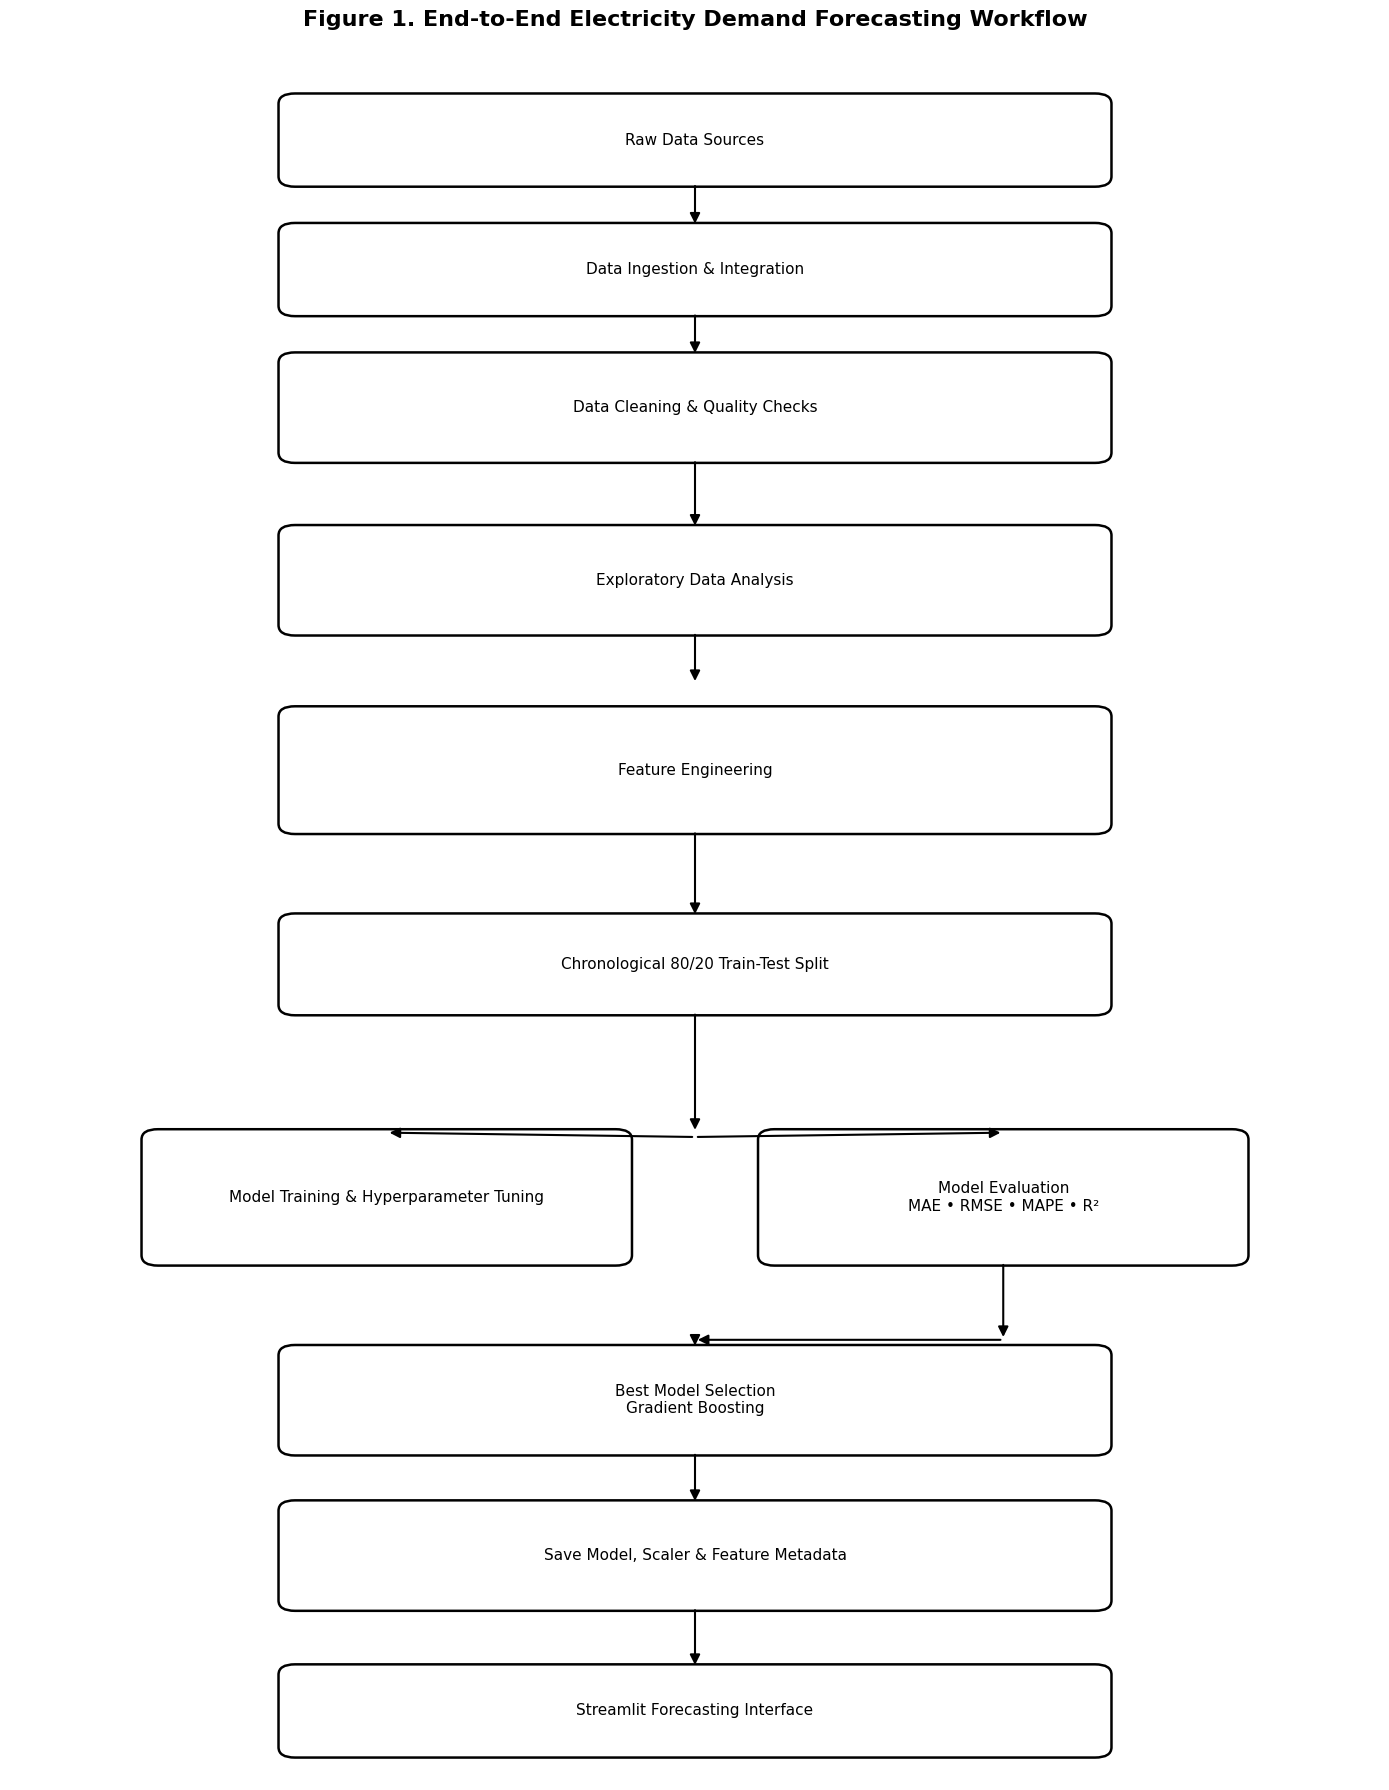

In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(14, 18))
ax.set_xlim(0, 10)
ax.set_ylim(0, 20)
ax.axis("off")

def add_box(x, y, w, h, text, fontsize=11):
    box = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.04,rounding_size=0.12",
        linewidth=1.8,
        facecolor="white",
        edgecolor="black"
    )
    ax.add_patch(box)
    ax.text(
        x + w / 2,
        y + h / 2,
        text,
        ha="center",
        va="center",
        fontsize=fontsize,
        wrap=True
    )

def add_arrow(x1, y1, x2, y2):
    arrow = FancyArrowPatch(
        (x1, y1),
        (x2, y2),
        arrowstyle="-|>",
        mutation_scale=15,
        linewidth=1.5,
        color="black"
    )
    ax.add_patch(arrow)

# Main blocks
boxes = [
    (2, 18.5, 6, 1.0, "Raw Data Sources"),
    (2, 17.0, 6, 1.0, "Data Ingestion & Integration"),
    (2, 15.3, 6, 1.2, "Data Cleaning & Quality Checks"),
    (2, 13.3, 6, 1.2, "Exploratory Data Analysis"),
    (2, 11.0, 6, 1.4, "Feature Engineering"),
    (2, 8.9, 6, 1.1, "Chronological 80/20 Train-Test Split"),
    (1.0, 6.0, 3.5, 1.5, "Model Training & Hyperparameter Tuning"),
    (5.5, 6.0, 3.5, 1.5, "Model Evaluation\nMAE • RMSE • MAPE • R²"),
    (2, 3.8, 6, 1.2, "Best Model Selection\nGradient Boosting"),
    (2, 2.0, 6, 1.2, "Save Model, Scaler & Feature Metadata"),
    (2, 0.3, 6, 1.0, "Streamlit Forecasting Interface")
]

for box in boxes:
    add_box(*box)

# Arrows
add_arrow(5, 18.5, 5, 18.0)
add_arrow(5, 17.0, 5, 16.5)
add_arrow(5, 15.3, 5, 14.5)
add_arrow(5, 13.3, 5, 12.7)
add_arrow(5, 11.0, 5, 10.0)
add_arrow(5, 8.9, 5, 7.5)

# Branch to models/evaluation
add_arrow(5, 7.45, 2.75, 7.5)
add_arrow(5, 7.45, 7.25, 7.5)

# Evaluation to selection
add_arrow(7.25, 6.0, 7.25, 5.1)
add_arrow(7.25, 5.1, 5.0, 5.1)
add_arrow(5.0, 5.1, 5.0, 5.0)

# Selection -> artifacts -> app
add_arrow(5, 3.8, 5, 3.2)
add_arrow(5, 2.0, 5, 1.3)

plt.title(
    "Figure 1. End-to-End Electricity Demand Forecasting Workflow",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.tight_layout()

# Required outputs
plt.savefig(
    "paper_figures/Fig1_workflow.png",
    dpi=320,
    bbox_inches="tight"
)

plt.savefig(
    "paper_figures/Fig1_workflow.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

###Fig. 2 — Demand distribution

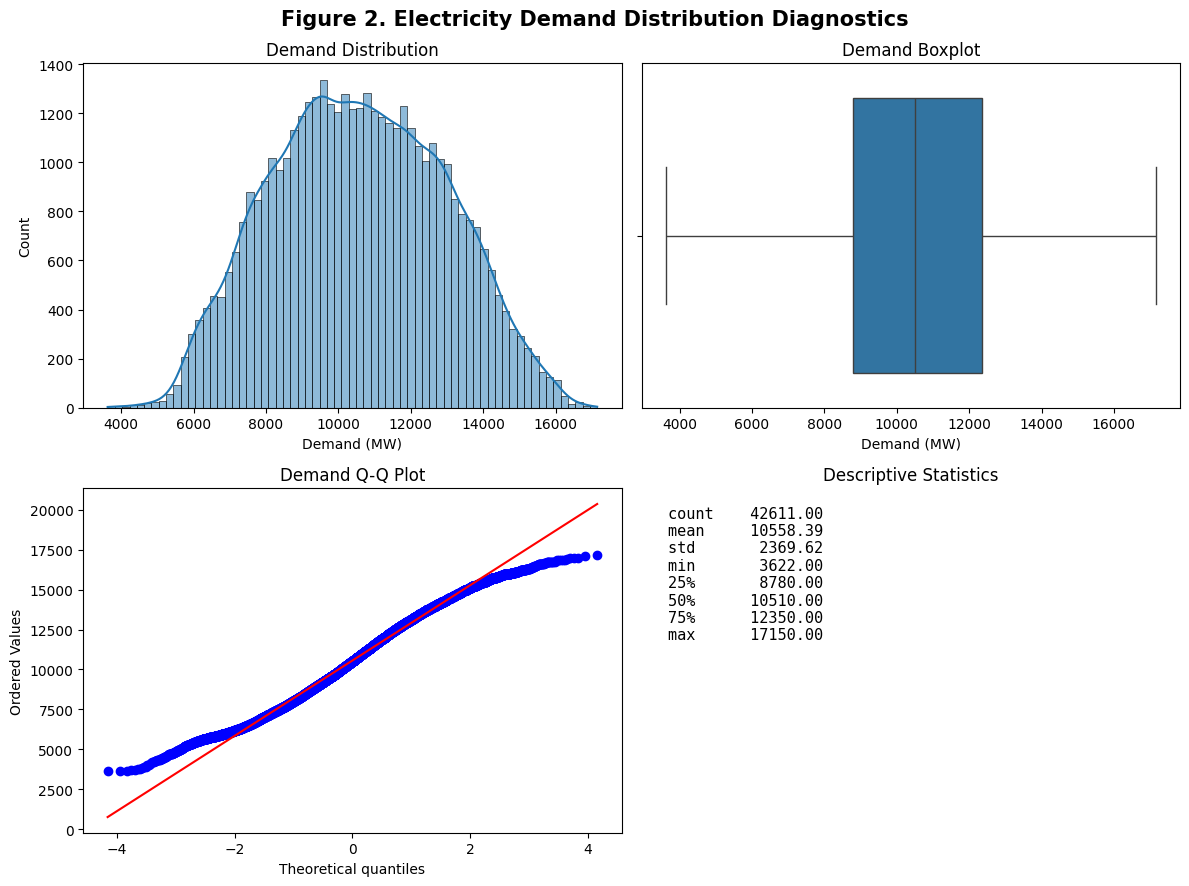

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv("cleaned_combined_data.csv")
df["datetime"] = pd.to_datetime(df["datetime"])
df = df.sort_values("datetime")

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Histogram + KDE
sns.histplot(
    df["demand_mw"].dropna(),
    kde=True,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Demand Distribution")
axes[0, 0].set_xlabel("Demand (MW)")

# Boxplot
sns.boxplot(
    x=df["demand_mw"],
    ax=axes[0, 1]
)
axes[0, 1].set_title("Demand Boxplot")
axes[0, 1].set_xlabel("Demand (MW)")

# Q-Q plot
stats.probplot(
    df["demand_mw"].dropna(),
    dist="norm",
    plot=axes[1, 0]
)
axes[1, 0].set_title("Demand Q-Q Plot")

# Statistics
stats_text = df["demand_mw"].describe().round(2).to_string()
axes[1, 1].axis("off")
axes[1, 1].text(
    0.05, 0.95,
    stats_text,
    va="top",
    family="monospace",
    fontsize=11
)
axes[1, 1].set_title("Descriptive Statistics")

plt.suptitle(
    "Figure 2. Electricity Demand Distribution Diagnostics",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "paper_figures/Fig2_demand_distribution.png",
    dpi=320,
    bbox_inches="tight"
)

plt.savefig(
    "paper_figures/Fig2_demand_distribution.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

Fig. 3 — Temperature distribution

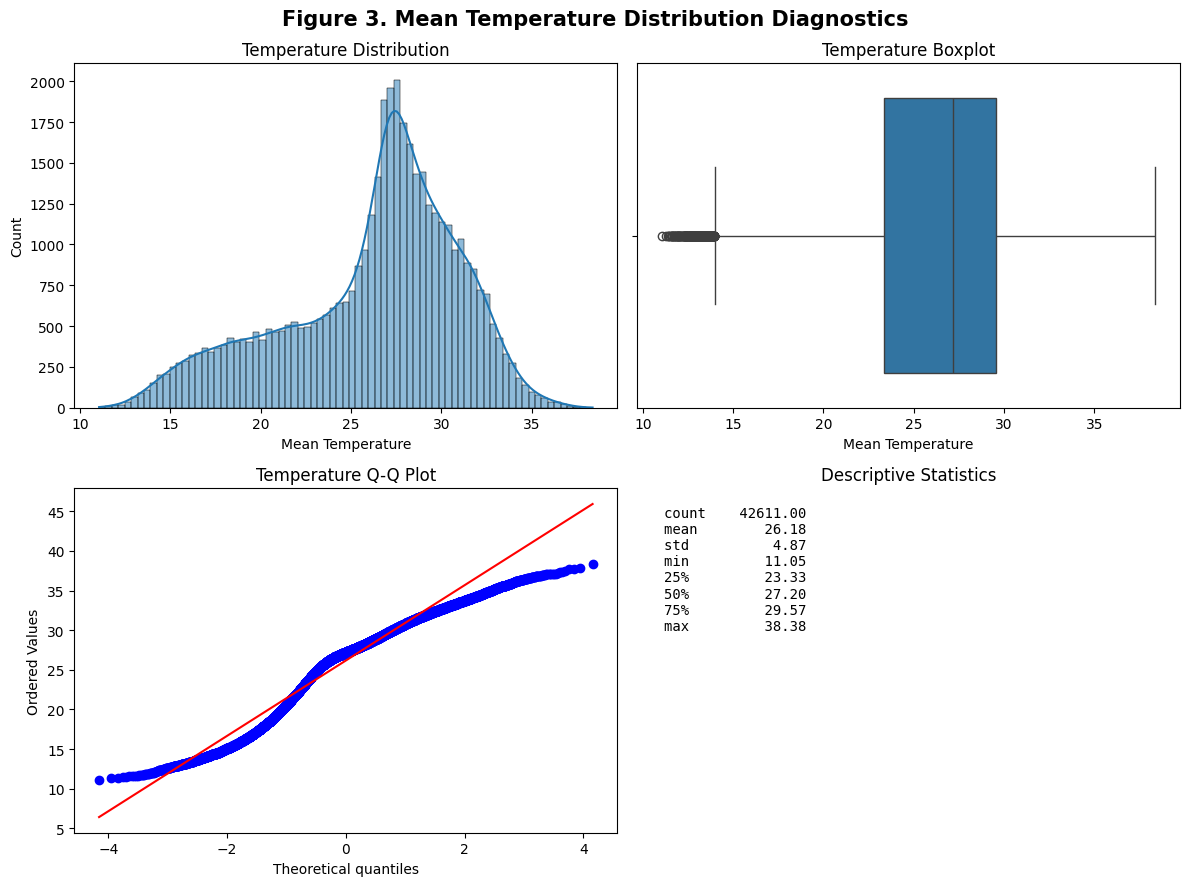

In [4]:
variable = "temp_mean"

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.histplot(df[variable].dropna(), kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Temperature Distribution")
axes[0, 0].set_xlabel("Mean Temperature")

sns.boxplot(x=df[variable], ax=axes[0, 1])
axes[0, 1].set_title("Temperature Boxplot")
axes[0, 1].set_xlabel("Mean Temperature")

stats.probplot(
    df[variable].dropna(),
    dist="norm",
    plot=axes[1, 0]
)
axes[1, 0].set_title("Temperature Q-Q Plot")

axes[1, 1].axis("off")
axes[1, 1].text(
    0.05,
    0.95,
    df[variable].describe().round(2).to_string(),
    va="top",
    family="monospace"
)
axes[1, 1].set_title("Descriptive Statistics")

plt.suptitle(
    "Figure 3. Mean Temperature Distribution Diagnostics",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig("paper_figures/Fig3_temperature_distribution.png",
            dpi=320, bbox_inches="tight")

plt.savefig("paper_figures/Fig3_temperature_distribution.svg",
            format="svg", bbox_inches="tight")

plt.show()

Fig. 4 — Wind-speed distribution

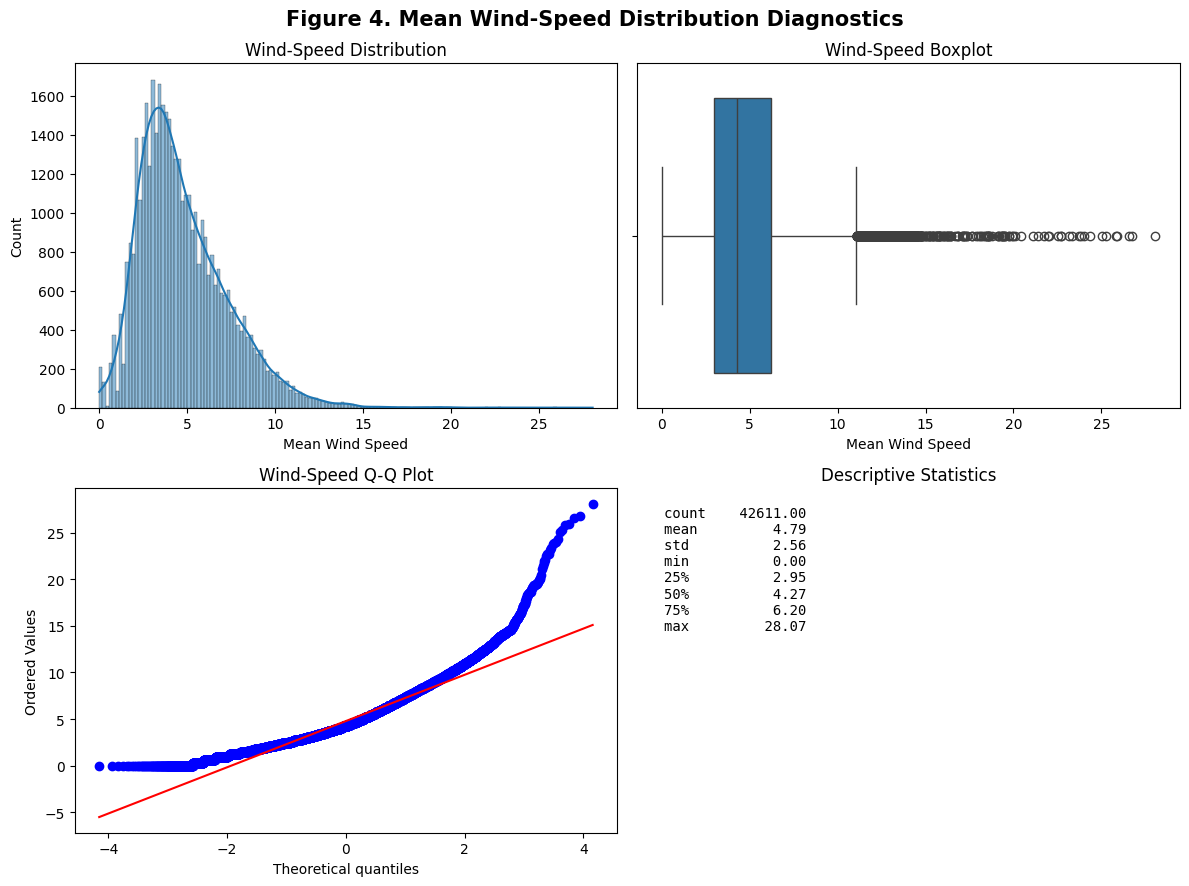

In [5]:
variable = "wspd_mean"

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.histplot(df[variable].dropna(), kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Wind-Speed Distribution")
axes[0, 0].set_xlabel("Mean Wind Speed")

sns.boxplot(x=df[variable], ax=axes[0, 1])
axes[0, 1].set_title("Wind-Speed Boxplot")
axes[0, 1].set_xlabel("Mean Wind Speed")

stats.probplot(
    df[variable].dropna(),
    dist="norm",
    plot=axes[1, 0]
)
axes[1, 0].set_title("Wind-Speed Q-Q Plot")

axes[1, 1].axis("off")
axes[1, 1].text(
    0.05,
    0.95,
    df[variable].describe().round(2).to_string(),
    va="top",
    family="monospace"
)
axes[1, 1].set_title("Descriptive Statistics")

plt.suptitle(
    "Figure 4. Mean Wind-Speed Distribution Diagnostics",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig("paper_figures/Fig4_wind_speed_distribution.png",
            dpi=320, bbox_inches="tight")

plt.savefig("paper_figures/Fig4_wind_speed_distribution.svg",
            format="svg", bbox_inches="tight")

plt.show()

Fig. 5 — Load-shedding diagnostics

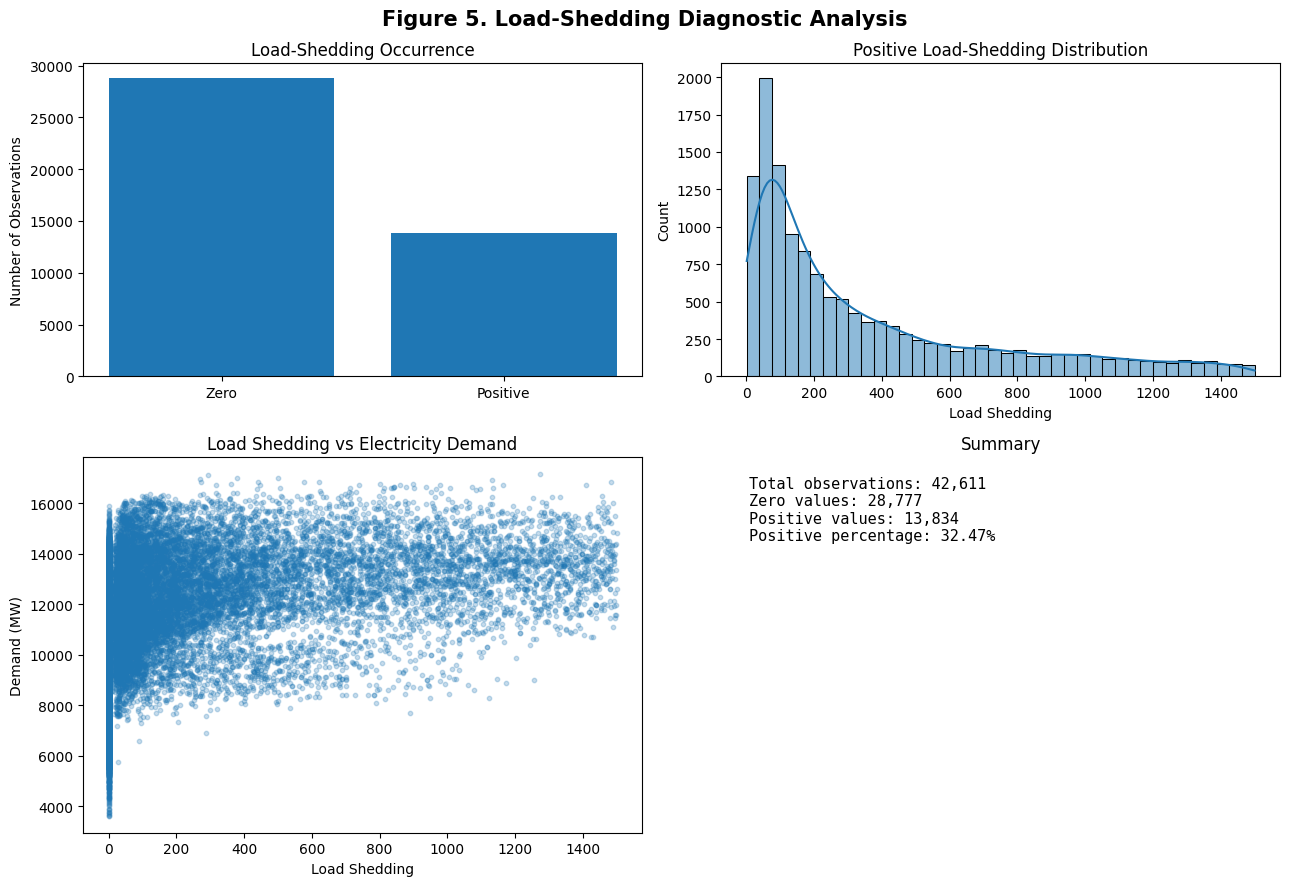

In [6]:
ls = df["load_shedding"]

zero_count = (ls == 0).sum()
positive_count = (ls > 0).sum()

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 9),
    gridspec_kw={"height_ratios": [1, 1.2]}
)

# Zero vs positive
axes[0, 0].bar(
    ["Zero", "Positive"],
    [zero_count, positive_count]
)
axes[0, 0].set_title("Load-Shedding Occurrence")
axes[0, 0].set_ylabel("Number of Observations")

# Positive-value distribution
positive_ls = ls[ls > 0]

sns.histplot(
    positive_ls,
    kde=True,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Positive Load-Shedding Distribution")
axes[0, 1].set_xlabel("Load Shedding")

# Relationship with demand
axes[1, 0].scatter(
    ls,
    df["demand_mw"],
    alpha=0.25,
    s=10
)
axes[1, 0].set_title("Load Shedding vs Electricity Demand")
axes[1, 0].set_xlabel("Load Shedding")
axes[1, 0].set_ylabel("Demand (MW)")

# Statistics
axes[1, 1].axis("off")

text = (
    f"Total observations: {len(df):,}\n"
    f"Zero values: {zero_count:,}\n"
    f"Positive values: {positive_count:,}\n"
    f"Positive percentage: "
    f"{positive_count / len(df) * 100:.2f}%"
)

axes[1, 1].text(
    0.05,
    0.95,
    text,
    va="top",
    fontsize=11,
    family="monospace"
)
axes[1, 1].set_title("Summary")

plt.suptitle(
    "Figure 5. Load-Shedding Diagnostic Analysis",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "paper_figures/Fig5_load_shedding_diagnostics.png",
    dpi=320,
    bbox_inches="tight"
)

plt.savefig(
    "paper_figures/Fig5_load_shedding_diagnostics.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

Fig. 6 — Correlation diagnostics

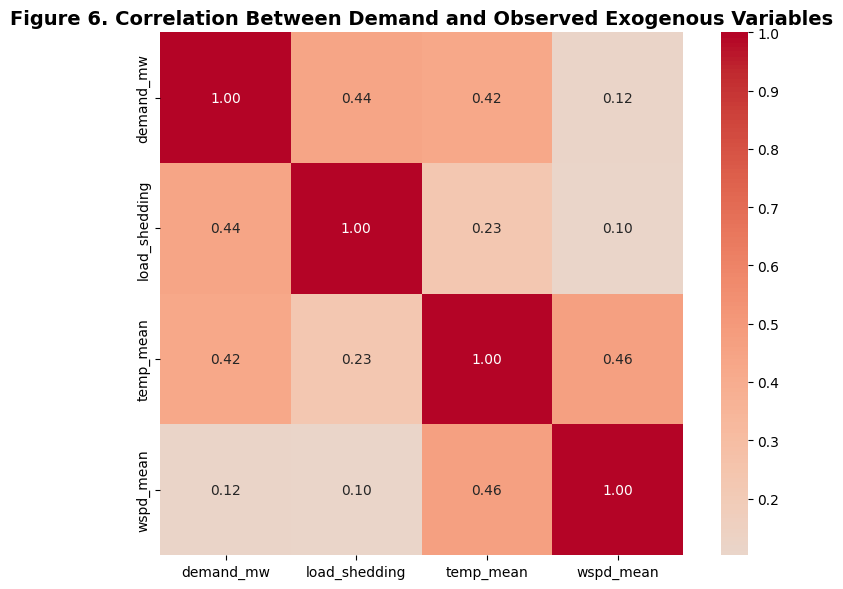

In [7]:
corr_cols = [
    "demand_mw",
    "load_shedding",
    "temp_mean",
    "wspd_mean"
]

corr = df[corr_cols].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title(
    "Figure 6. Correlation Between Demand and Observed Exogenous Variables",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "paper_figures/Fig6_feature_correlation_diagnostics.png",
    dpi=320,
    bbox_inches="tight"
)

plt.savefig(
    "paper_figures/Fig6_feature_correlation_diagnostics.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

Fig. 7 — Temporal stability

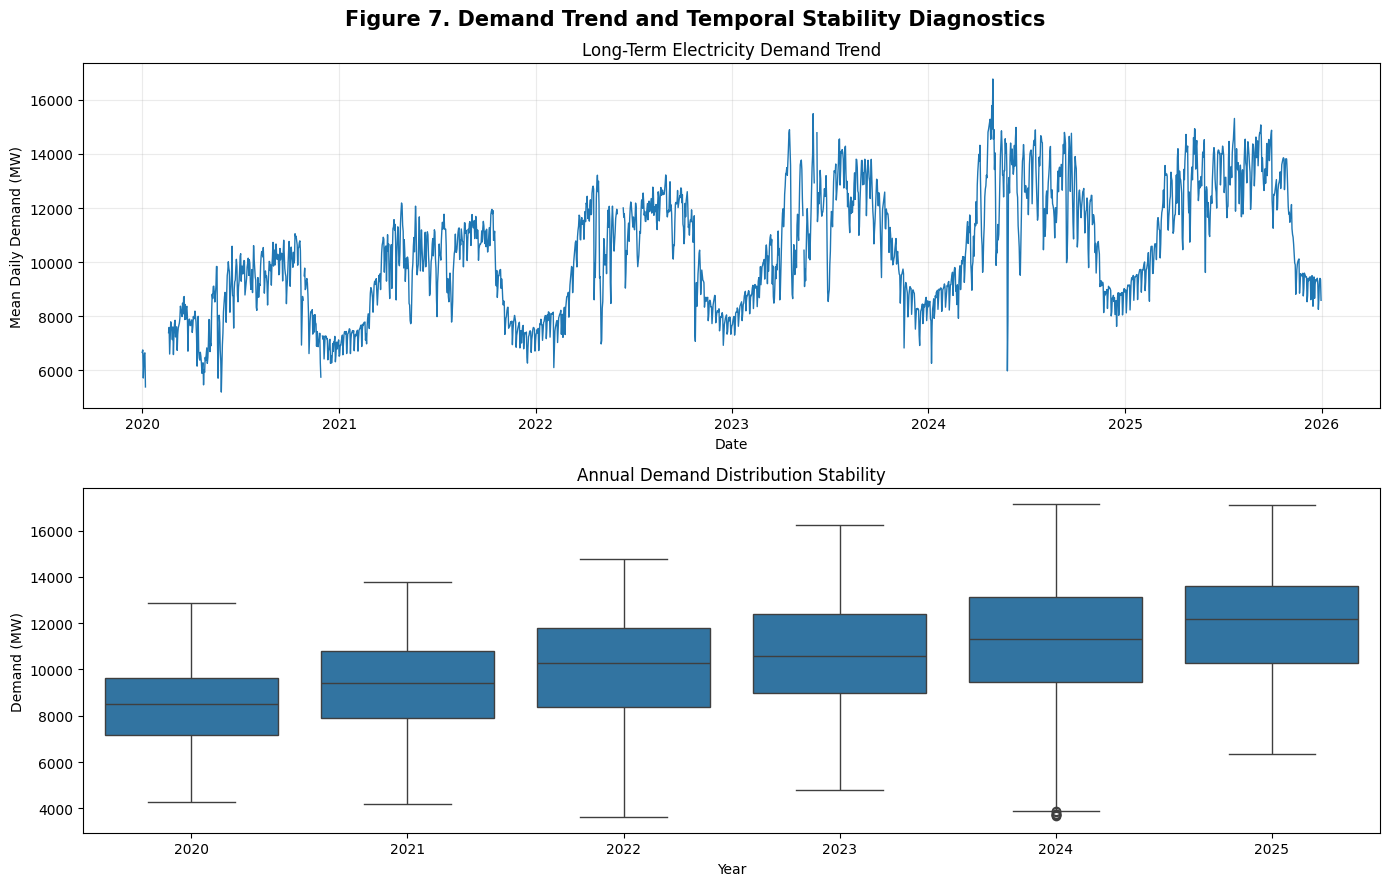

In [8]:
df["year"] = df["datetime"].dt.year

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

# Long-term trend
daily_demand = (
    df.set_index("datetime")["demand_mw"]
      .resample("D")
      .mean()
)

axes[0].plot(
    daily_demand.index,
    daily_demand.values,
    linewidth=1
)

axes[0].set_title("Long-Term Electricity Demand Trend")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Mean Daily Demand (MW)")
axes[0].grid(alpha=0.25)

# Annual distribution
sns.boxplot(
    data=df,
    x="year",
    y="demand_mw",
    ax=axes[1]
)

axes[1].set_title("Annual Demand Distribution Stability")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Demand (MW)")

plt.suptitle(
    "Figure 7. Demand Trend and Temporal Stability Diagnostics",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "paper_figures/Fig7_temporal_stability_diagnostics.png",
    dpi=320,
    bbox_inches="tight"
)

plt.savefig(
    "paper_figures/Fig7_temporal_stability_diagnostics.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()